# 03 · Componente no supervisado — segmentación de clientes
**Objetivo:** descubrir perfiles de clientes **sin usar `y`** y analizar después su relación con la
aceptación del depósito.

## 1. Selección y justificación de algoritmos
| Algoritmo | Por qué | Supuestos | Ventajas | Limitaciones |
|---|---|---|---|---|
| K-Means | Estándar para segmentación | Clusters esféricos de tamaño similar | Rápido, interpretable | Sensible a escala y atípicos; hay que fijar k |
| Mezcla gaussiana (GMM) | Clusters elípticos y asignación probabilística | Datos ≈ mezcla de gaussianas | Más flexible que K-Means | Más costoso, sensible a inicialización |
| Jerárquico (Ward) | Verificar la estabilidad de la estructura | Clusters compactos | Dendrograma, sin inicialización | O(n²): requiere muestra |

La justificación completa (preparación de datos, supuestos y optimización) está en `docs/03_modelos_no_supervisados.md`.

In [1]:
import sys
sys.path.append("..")   # permite `from src import ...` al ejecutar desde notebooks/

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.data_loader import get_train_test, load_data

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
config.RESULTS_DIR.mkdir(parents=True, exist_ok=True)

X_train, X_test, y_train, y_test = get_train_test()
print("Train:", X_train.shape, "| Test:", X_test.shape)

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score
from src import unsupervised as uns

Train: (36168, 15) | Test: (9043, 15)


## 2. Matriz de trabajo
Preprocesamiento ajustado con entrenamiento + **PCA (90 % de varianza)** para que las distancias tengan
sentido con variables mezcladas (numéricas + one-hot). `y` no entra en este paso.

In [2]:
Z, _, prep, pca = uns.prepare_matrix(X_train)
print("Dimensión tras PCA:", Z.shape, "| varianza explicada:", pca.explained_variance_ratio_.sum().round(3))

Dimensión tras PCA: (36168, 14) | varianza explicada: 0.908


## 3. Elección de k (codo + Silhouette + Davies-Bouldin)

,k,inercia,silhouette,davies_bouldin,calinski_harabasz
0,2,334974.724,0.305,1.657,8602.438
1,3,300963.099,0.145,2.122,6830.673
2,4,272886.702,0.164,1.906,6262.433
3,5,252600.896,0.170,1.845,5799.919
4,6,235280.773,0.172,1.762,5513.775
5,7,223685.522,0.159,1.768,5145.267
6,8,214904.199,0.141,1.809,4801.399
7,9,207668.509,0.141,1.770,4504.978
8,10,200725.310,0.145,1.750,4281.785


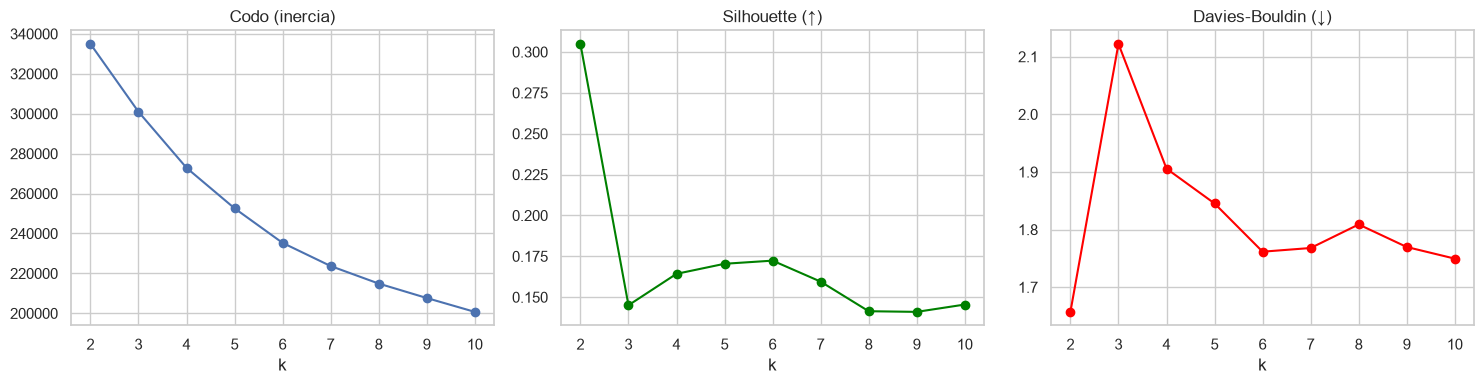

In [3]:
sweep = uns.sweep_kmeans(Z, range(2, 11))
display(sweep.round(3))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(sweep["k"], sweep["inercia"], marker="o"); axes[0].set_title("Codo (inercia)")
axes[1].plot(sweep["k"], sweep["silhouette"], marker="o", color="green"); axes[1].set_title("Silhouette (↑)")
axes[2].plot(sweep["k"], sweep["davies_bouldin"], marker="o", color="red"); axes[2].set_title("Davies-Bouldin (↓)")
for ax in axes: ax.set_xlabel("k")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "uns_eleccion_k.png", dpi=150); plt.show()
sweep.to_csv(config.RESULTS_DIR / "no_supervisado_barrido_k.csv", index=False)

**Decisión:** se elige **k = 4**.
- El Silhouette máximo está en k = 2 (0,305), pero esa partición solo separa a los clientes que nunca habían sido
  contactados (82 %) de los que sí (18 %), algo que ya era evidente en `pdays` durante el EDA: no aporta segmentos nuevos.
- Entre k = 4 y k = 6 el Silhouette casi no cambia (0,164 → 0,172) y Davies-Bouldin baja poco (1,91 → 1,76); el codo
  de la inercia se suaviza a partir de k = 4. Con k = 6 aparecen grupos que repiten perfiles ya vistos con k = 4.
- k = 4 produce segmentos **interpretables** y con tamaños útiles para una campaña (el más pequeño tiene el 7,7 % de
  los clientes) y, como se ve en la sección 8, con tasas de aceptación muy distintas.

In [4]:
K = 4   # elegido: ver la decisión anterior

## 4. Entrenamiento y comparación de algoritmos

In [5]:
km = uns.fit_kmeans(Z, K);  labels_km = km.labels_
gmm = uns.fit_gmm(Z, K);    labels_gmm = gmm.predict(Z)
idx_h, labels_h = uns.fit_agglomerative(Z, K)       # sobre muestra

res = pd.DataFrame({
    "K-Means": uns.clustering_metrics(Z, labels_km),
    "GMM": uns.clustering_metrics(Z, labels_gmm),
    "Jerárquico (muestra)": uns.clustering_metrics(Z[idx_h], labels_h),
}).T
display(res.round(3))
res.to_csv(config.RESULTS_DIR / "no_supervisado_comparacion.csv")
print("Acuerdo K-Means vs GMM (ARI):", round(adjusted_rand_score(labels_km, labels_gmm), 3))
print("Acuerdo K-Means vs Jerárquico (ARI, en la muestra):", round(adjusted_rand_score(labels_km[idx_h], labels_h), 3))

,silhouette,davies_bouldin,calinski_harabasz
K-Means,0.164,1.906,6262.433
GMM,0.090,3.702,4239.203
Jerárquico (muestra),0.164,1.861,1184.599


Acuerdo K-Means vs GMM (ARI): 0.549
Acuerdo K-Means vs Jerárquico (ARI, en la muestra): 0.345


**Interpretación:** **K-Means** separa mejor: tiene el mayor Silhouette (0,164, igual que el jerárquico en su
muestra), el menor Davies-Bouldin del conjunto completo (1,91) y el mayor Calinski-Harabasz (6.262). GMM queda claramente
por debajo (Silhouette 0,090, Davies-Bouldin 3,70) porque con k = 4 sus componentes se solapan.
El acuerdo entre algoritmos es **moderado** (ARI = 0,55 con GMM y 0,35 con el jerárquico): coinciden en la división
principal (contactados antes vs. nuevos) pero no en los bordes. Junto con un Silhouette bajo (< 0,2), esto indica que
los clientes no forman grupos muy separados sino un **continuo**, y que los segmentos son una forma útil de
resumirlo más que clusters "naturales".

## 5. Optimización y estabilidad de los modelos
- **GMM:** elegimos el tipo de covarianza y k con **BIC/AIC** (criterios de información: penalizan la complejidad).
- **Jerárquico:** comparamos criterios de enlace (ward, average, complete) sobre una muestra.
- **K-Means:** medimos la **estabilidad** repitiendo con distintas semillas (ARI = 1 → mismos grupos siempre).

covarianza,diag,full,spherical
k,,,
2,1134068.0,594061.0,1252352.0
3,1106452.0,481888.0,1223010.0
4,1082240.0,267369.0,1207133.0
5,1070238.0,231566.0,1180830.0
6,1034996.0,156829.0,1176148.0
7,1017351.0,109432.0,1138514.0
8,1006742.0,157104.0,1124212.0


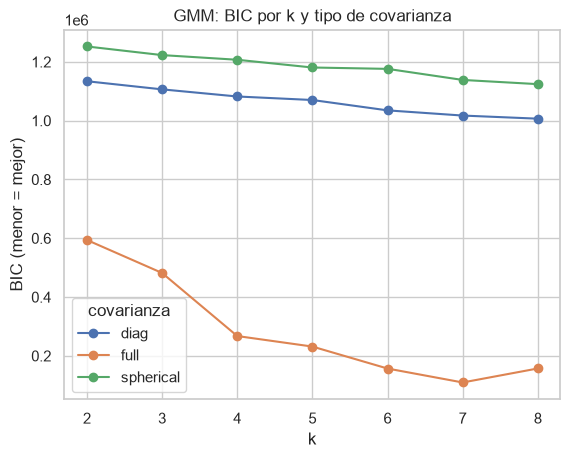

In [6]:
bic = uns.sweep_gmm_bic(Z, range(2, 9))
display(bic.pivot(index="k", columns="covarianza", values="bic").round(0))
for cov, g in bic.groupby("covarianza"):
    plt.plot(g["k"], g["bic"], marker="o", label=cov)
plt.xlabel("k"); plt.ylabel("BIC (menor = mejor)"); plt.legend(title="covarianza"); plt.title("GMM: BIC por k y tipo de covarianza")
plt.savefig(config.FIGURES_DIR / "uns_gmm_bic.png", dpi=150, bbox_inches="tight"); plt.show()
bic.to_csv(config.RESULTS_DIR / "no_supervisado_gmm_bic.csv", index=False)

In [7]:
link = uns.compare_linkages(Z, K, sample_size=4000)
display(link.round(3))
stab = uns.kmeans_stability(Z, K, n_runs=10)
print("Estabilidad K-Means (ARI entre 10 semillas):", {k: round(v, 3) for k, v in stab.items()})
link.to_csv(config.RESULTS_DIR / "no_supervisado_linkages.csv")

,silhouette,davies_bouldin,calinski_harabasz,cluster_mas_grande
ward,0.116,2.149,593.389,0.497
average,0.282,1.351,333.207,0.823
complete,0.285,1.422,428.734,0.808


Estabilidad K-Means (ARI entre 10 semillas): {'ari_medio': 0.794, 'ari_min': 0.587}


**Interpretación:**
- **GMM:** el BIC prefiere siempre la covarianza **full** (mucho menor que diag y spherical) y alcanza su mínimo en
  **k = 7**, no en k = 4. Con covarianzas completas el modelo describe mejor la *densidad* de los datos usando más
  componentes, pero esos componentes no son necesariamente segmentos interpretables; por eso no se sigue el BIC para
  elegir k y se mantiene K-Means como modelo final.
- **Jerárquico:** *average* y *complete* tienen mejor Silhouette (≈ 0,28), pero un solo cluster absorbe el 82 % y el
  81 % de los clientes: separan unos pocos atípicos y no segmentan. *Ward* produce grupos más equilibrados (el mayor
  tiene el 50 %), aunque con menor Silhouette (0,12). Para segmentar se prefieren grupos equilibrados.
- **Estabilidad de K-Means:** ARI medio de **0,79** entre 10 semillas (mínimo 0,59). Los grupos son razonablemente
  estables, aunque algunas inicializaciones cambian la frontera entre segmentos.

## 6. Visualización y reducción de dimensionalidad

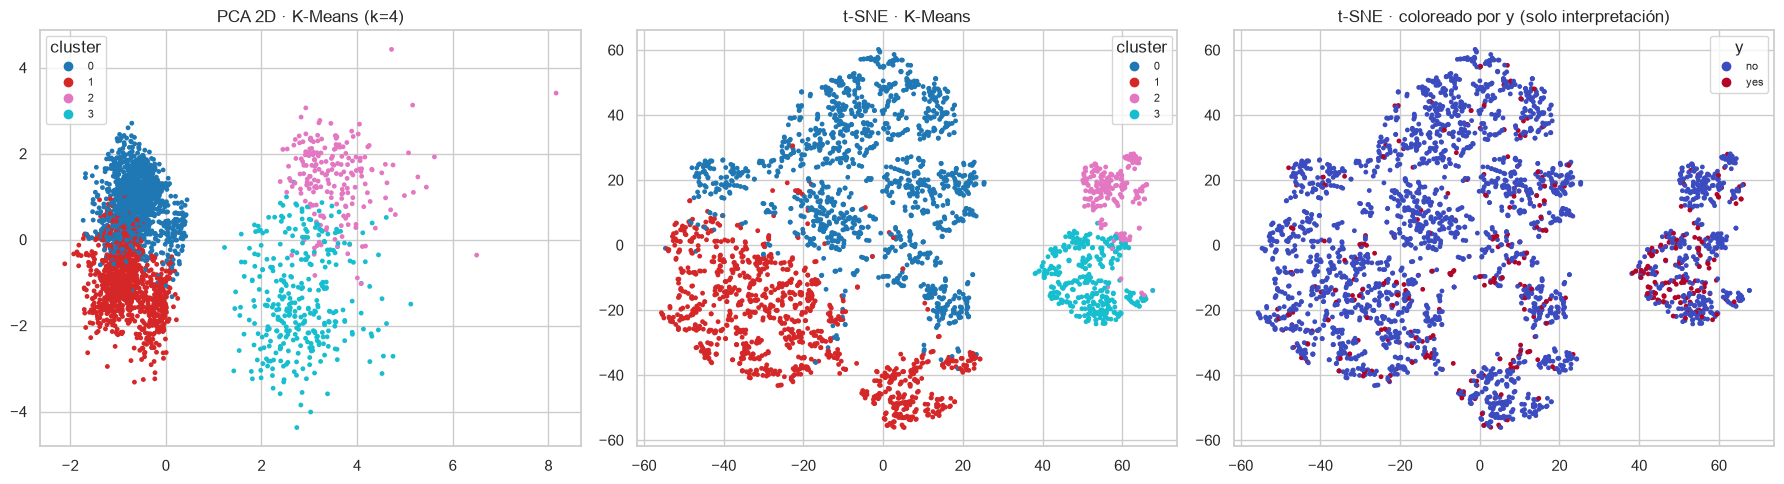

Varianza explicada por los 2 primeros componentes (sobre Z): 0.343


In [8]:
rng = np.random.RandomState(config.RANDOM_STATE)
s = rng.choice(len(Z), size=3000, replace=False)           # muestra para t-SNE
pca2 = PCA(n_components=2, random_state=config.RANDOM_STATE)
P = pca2.fit_transform(Z)
tsne = TSNE(n_components=2, perplexity=30, random_state=config.RANDOM_STATE, init="pca").fit_transform(Z[s])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sc0 = axes[0].scatter(P[s, 0], P[s, 1], c=labels_km[s], cmap="tab10", s=6); axes[0].set_title(f"PCA 2D · K-Means (k={K})")
sc1 = axes[1].scatter(tsne[:, 0], tsne[:, 1], c=labels_km[s], cmap="tab10", s=6); axes[1].set_title("t-SNE · K-Means")
sc2 = axes[2].scatter(tsne[:, 0], tsne[:, 1], c=y_train.values[s], cmap="coolwarm", s=6); axes[2].set_title("t-SNE · coloreado por y (solo interpretación)")
for ax, sc in [(axes[0], sc0), (axes[1], sc1)]:
    ax.legend(*sc.legend_elements(), title="cluster", fontsize=8)
axes[2].legend(sc2.legend_elements()[0], ["no", "yes"], title="y", fontsize=8)
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "uns_visualizacion.png", dpi=150); plt.show()
print("Varianza explicada por los 2 primeros componentes (sobre Z):", pca2.explained_variance_ratio_.sum().round(3))

**Interpretación:** los dos primeros componentes de PCA conservan solo el **34 %** de la varianza de la matriz
de trabajo, pero bastan para ver la estructura principal: el primer componente separa con claridad a los clientes
**nuevos** (clusters 0 y 1, a la izquierda) de los **recontactados** (clusters 2 y 3, a la derecha), y el segundo
separa cada par. Las fronteras dentro de cada lado sí se solapan, porque parte de la diferencia está en las otras
12 dimensiones. t-SNE conserva la **vecindad local** pero no las distancias globales ni el tamaño de los grupos (no
sirve para medir qué tan lejos están dos segmentos); aun así muestra la misma división en dos "islas". En el panel
coloreado por `y`, los clientes que aceptan aparecen dispersos en todos los segmentos, pero son visiblemente más
frecuentes en la isla de los recontactados, lo que anticipa la relación de la sección 8.

## 7. Perfiles de clientes

In [9]:
profile = uns.profile_clusters(X_train, labels_km)
display(profile.T)
profile.to_csv(config.RESULTS_DIR / "no_supervisado_perfiles.csv")

cluster,0,1,2,3
proporcion,0.455983,0.361977,0.077195,0.104844
age,39.68,42.41,38.97,42.34
balance,1207.66,1464.61,1072.56,1925.41
day,13.94,18.96,12.39,15.66
campaign,2.54,3.4,2.18,1.96
pdays,-1.0,-1.0,337.36,142.43
previous,0.0,0.0,3.15,3.23
contact,unknown,cellular,cellular,cellular
default,no,no,no,no
education,secondary,secondary,secondary,secondary


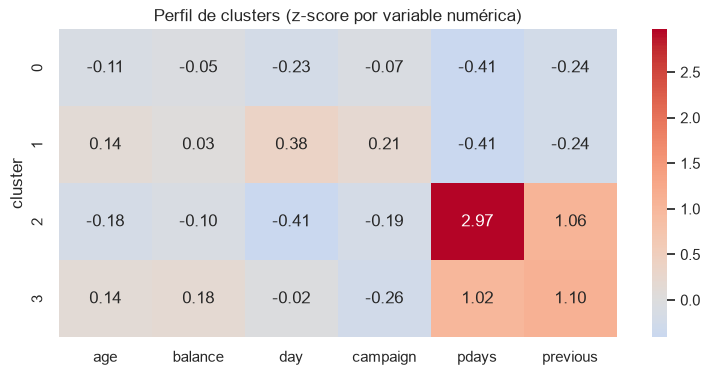

In [10]:
# Perfil visual: media estandarizada de las variables numéricas por cluster
num = X_train.select_dtypes(include=np.number)
zmean = ((num - num.mean()) / num.std()).assign(cluster=labels_km).groupby("cluster").mean()
plt.figure(figsize=(9, 4)); sns.heatmap(zmean, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Perfil de clusters (z-score por variable numérica)")
plt.savefig(config.FIGURES_DIR / "uns_perfiles.png", dpi=150, bbox_inches="tight"); plt.show()

**Perfiles:**

| Cluster | Nombre | Tamaño | Descripción |
|---|---|---|---|
| 0 | **Nuevos sin canal registrado** | 45,6 % | Nunca contactados antes. El 61 % tiene canal de contacto *unknown*; contactados sobre todo en mayo-junio; 70 % con crédito hipotecario; predominan obreros (*blue-collar*). Edad y balance promedio. |
| 1 | **Nuevos de verano contactados por celular** | 36,2 % | Nunca contactados antes; 89 % por celular, principalmente en julio-agosto y en la segunda mitad del mes; 65 % sin hipoteca; más perfiles *management* y técnicos; reciben más llamadas en la campaña (3,4 en promedio). |
| 2 | **Recontactados antiguos con campaña fallida** | 7,7 % | Contactados en una campaña anterior hace casi un año (`pdays` ≈ 337 días); el 69 % con resultado previo *failure*; 84 % con hipoteca; los más jóvenes y con menor balance. |
| 3 | **Recontactados recientes con historial positivo** | 10,5 % | Contactados hace unos 140 días; el 28 % tuvo **éxito** en la campaña anterior; el **mayor balance** (≈ 1.925); reciben menos llamadas (1,96); contacto más repartido en el año (noviembre es el mes más frecuente). |

## 8. Relación entre los segmentos y la aceptación (ahora sí se usa `y`)

,clientes,tasa_aceptacion
cluster,,
0,16492,0.090
1,13092,0.095
2,2792,0.134
3,3792,0.298


Tasa global de aceptación: 0.117 | chi2=1392.0, p=1.58e-301


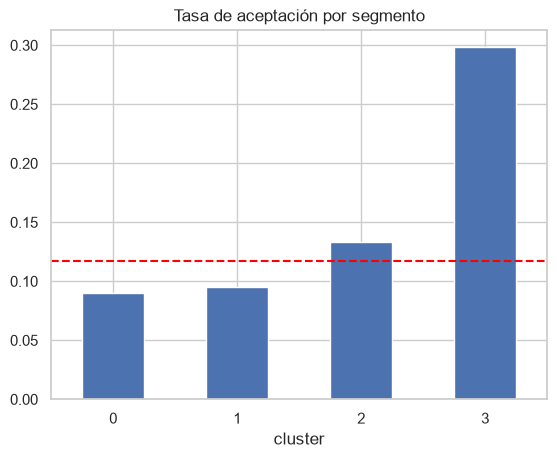

In [11]:
tabla, chi = uns.cluster_vs_target(labels_km, y_train)
display(tabla.round(3))
print(f"Tasa global de aceptación: {y_train.mean():.3f} | chi2={chi['chi2']:.1f}, p={chi['p_valor']:.2e}")
tabla["tasa_aceptacion"].plot(kind="bar", color="#4C72B0", rot=0)
plt.axhline(y_train.mean(), color="red", ls="--"); plt.title("Tasa de aceptación por segmento")
plt.savefig(config.FIGURES_DIR / "uns_aceptacion_por_cluster.png", dpi=150, bbox_inches="tight"); plt.show()
tabla.to_csv(config.RESULTS_DIR / "no_supervisado_aceptacion.csv")

## 9. Conclusiones y recomendaciones de campaña
- **Segmentos con mayor y menor aceptación:** los **recontactados recientes con historial positivo** (cluster 3) aceptan
  el **29,8 %**, 2,5 veces la tasa global (11,7 %), porque incluyen clientes que ya aceptaron una oferta antes y tienen
  más ahorro. Los recontactados antiguos (cluster 2) aceptan el 13,4 %. Los dos segmentos de clientes nuevos (clusters 0
  y 1), que son el 82 % de la base, aceptan solo el 9,0 % y el 9,5 %. La diferencia es significativa
  (χ² = 1.392, p ≈ 1,6·10⁻³⁰¹).
- **Recomendaciones:** priorizar a los clientes del cluster 3 (recontacto temprano, sin saturarlos con llamadas); en los
  clientes nuevos, usar **celular** como canal (acepta el 14,8 % frente al 4,1 % del canal desconocido, que
  predomina en el cluster 0) y no concentrar la campaña en mayo, el mes con más llamadas (31 % del total) y la menor
  aceptación (6,7 %); con los recontactados de campañas fallidas, cambiar la oferta en lugar de repetirla.
- **Limitaciones:** el Silhouette es bajo (0,16), por lo que los segmentos son una partición útil de un continuo y no
  grupos naturales; las variables mezcladas (numéricas + one-hot) obligan a reducir con PCA y se pierde ~9 % de la
  varianza; la estabilidad de K-Means es buena pero no perfecta (ARI medio 0,79); y k = 4 se eligió por
  interpretabilidad, no por una métrica única (el BIC del GMM sugiere 7 componentes).
- **Estructuras no evidentes en el EDA:** el EDA ya mostraba que el historial de contacto (`pdays`, `poutcome`) se
  relaciona con la aceptación, pero el clustering reveló, **sin usar `y`**, que los clientes nuevos se dividen en dos
  perfiles distintos (canal desconocido y mayo vs. celular y verano) con aceptación similar, y que entre los
  recontactados hay un grupo pequeño (10,5 %) que concentra la mayor probabilidad de éxito.